# Citi Bike EDA — 合成数据运行验证

当前展示为 **synthetic**，不代表 NYC 真实统计或真实服务损失。核心逻辑在 src/report.py；此 notebook 读取保存产物并做诊断。

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
assert (ROOT/'src').exists(), 'Run from repository root'
data=ROOT/'data/demo'
out=ROOT/'outputs/demo'
panel=pd.read_parquet(data/'panel.parquet')
print('SYNTHETIC DATA ONLY', panel.shape)
display(pd.read_csv(data/'data_quality_summary.csv'))

SYNTHETIC DATA ONLY (262800, 9)


,data_kind,months,complete_year,stations,panel_rows,unknown_hours,source,count_conservation
0,synthetic,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]",True,30,262800,0,seeded independent Poisson counts; no real rides,synthetic_counts_only


,hour,departures,arrivals,total
0,2025-06-12 00:00:00+00:00,5049,5013,10062
1,2025-06-06 00:00:00+00:00,5098,4954,10052
2,2025-06-25 00:00:00+00:00,4934,5041,9975
3,2025-07-04 00:00:00+00:00,4957,5017,9974
4,2025-06-17 00:00:00+00:00,5006,4968,9974


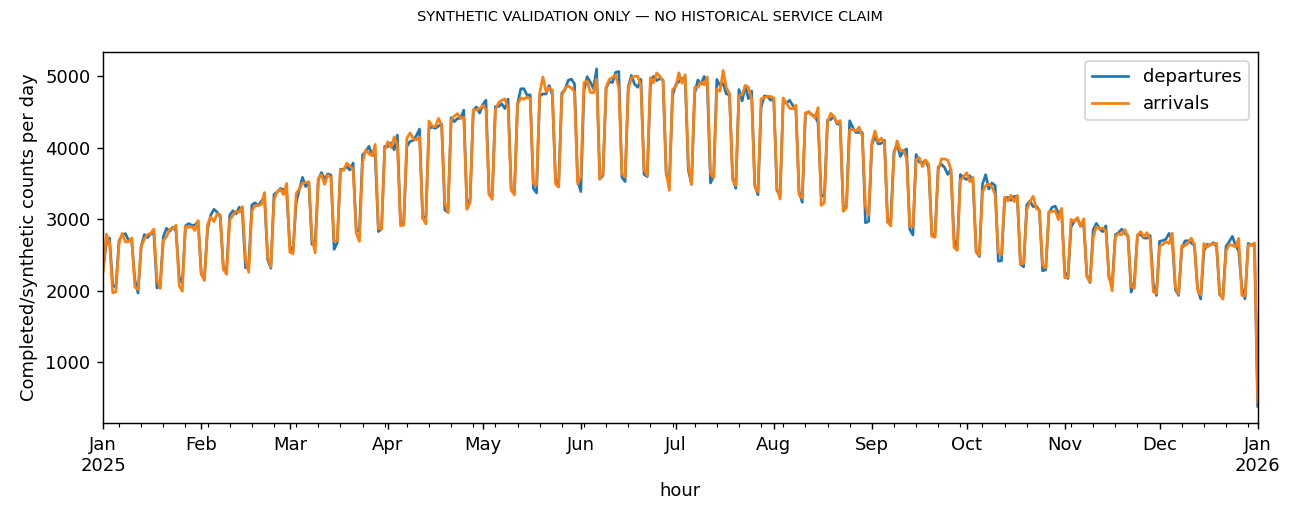

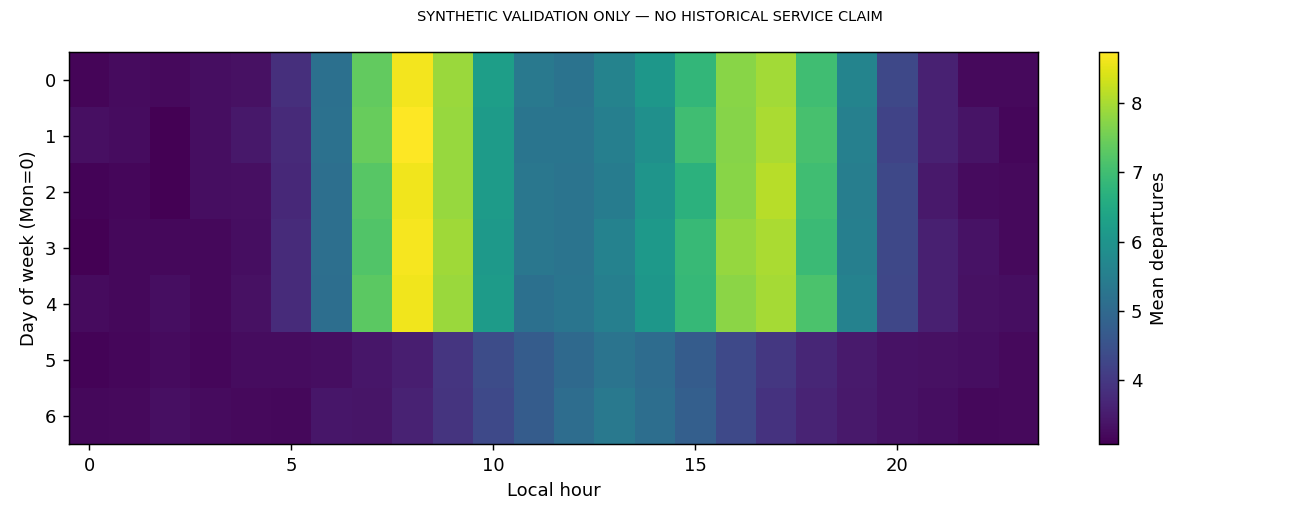

In [2]:
display(pd.read_csv(out/'anomalous_dates.csv').head())
display(Image(filename=str(out/'figures/eda_daily.png')))
display(Image(filename=str(out/'figures/eda_heatmap.png')))

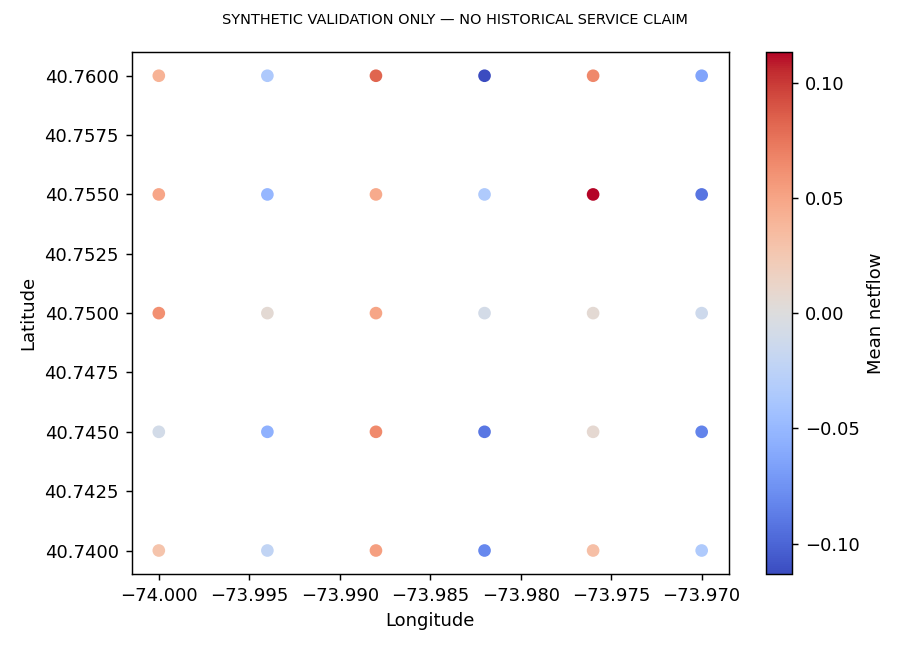

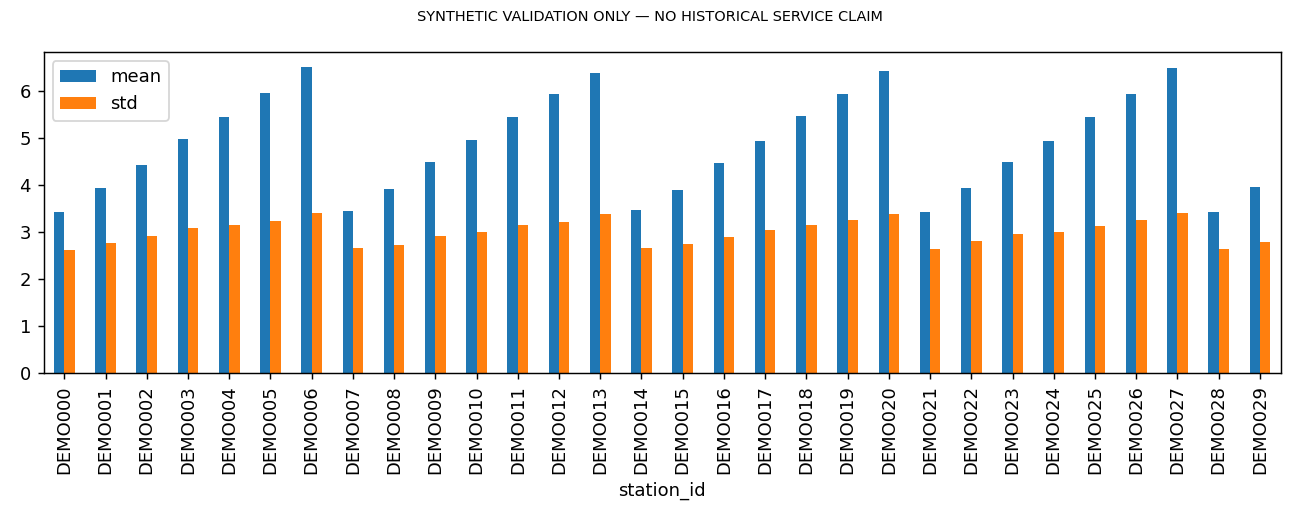

,station_id,mean,std,min,median,max
0,DEMO000,0.028539,2.749729,-12,0.0,13
1,DEMO001,-0.021461,2.952800,-12,0.0,20
2,DEMO002,0.053653,3.141173,-15,0.0,19
3,DEMO003,-0.081279,3.226045,-14,0.0,17
4,DEMO004,0.032648,3.389316,-20,0.0,17


In [3]:
display(Image(filename=str(out/'figures/eda_map.png')))
display(Image(filename=str(out/'figures/eda_heterogeneity.png')))
display(pd.read_csv(out/'station_netflow_distribution.csv').head())

,model,target,split,stratum,n,mae,rmse,wape
2,last_hour,departures,test,all,43950,2.080478,2.715820,0.589832
5,seasonal_naive,departures,test,all,43950,2.054903,2.680843,0.582582
8,poisson,departures,test,all,43950,1.579417,2.002112,0.447778
11,xgboost,departures,test,all,43950,1.503246,1.915562,0.426183
14,last_hour,arrivals,test,all,43950,2.080364,2.734277,0.590841
17,seasonal_naive,arrivals,test,all,43950,2.054653,2.688525,0.583539
20,poisson,arrivals,test,all,43950,1.602377,2.043549,0.455088
23,xgboost,arrivals,test,all,43950,1.532614,1.971678,0.435275


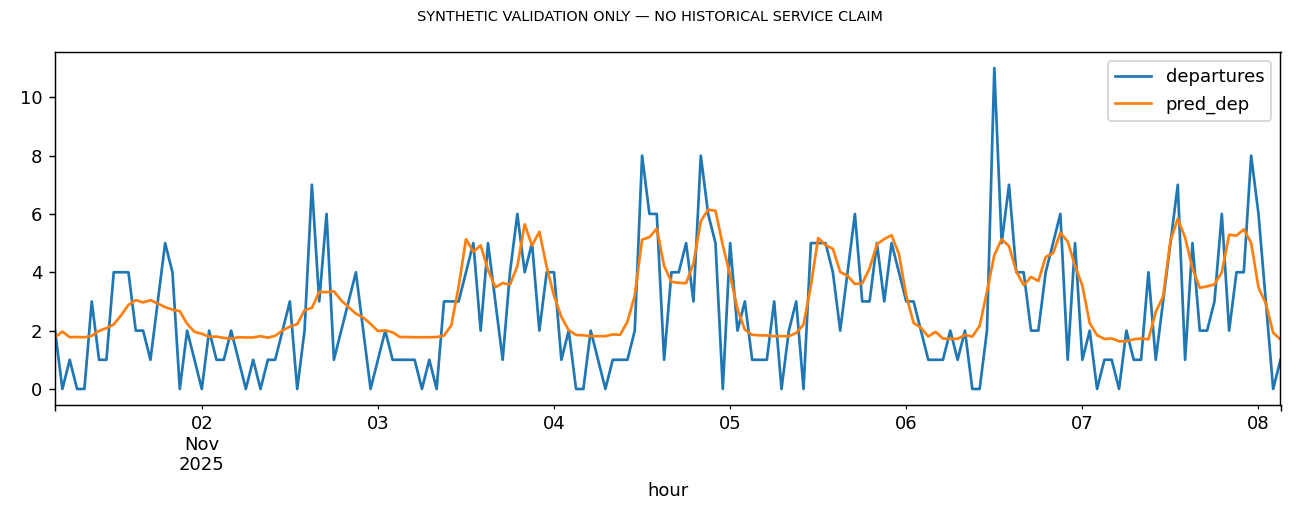

In [4]:
metrics=pd.read_csv(out/'forecast_metrics.csv')
display(metrics[(metrics.split=='test') & (metrics.stratum=='all')])
display(Image(filename=str(out/'figures/forecast_trace.png')))

In [5]:
display(pd.read_csv(out/'simulation_summary.csv'))
display(pd.read_csv(out/'uncertainty_summary.csv'))
print('Hourly count-based scenario simulation; no historical service claim.')

,strategy,departure_requests,arrival_events,unmet_departures,blocked_arrivals,bikes_moved,bike_km,scenario_objective,proxy_service_rate,mean_runtime_ms,fallback_hours,data_kind,simulation_kind,hours
0,none,37925,37835,1542,1505,0,0.000000,15235.000000,0.959341,0.415443,0,synthetic,hourly count-based scenario simulation,336
1,greedy,37925,37835,647,613,3971,2043.372925,6504.337293,0.982940,0.588100,0,synthetic,hourly count-based scenario simulation,336
2,milp,37925,37835,165,161,3424,2854.709444,1915.470944,0.995649,8.430810,0,synthetic,hourly count-based scenario simulation,336


,strategy,baseline,metric,days,ci_low,ci_high,method
0,greedy,none,daily_scenario_objective_difference,14,-705.956376,-547.081942,paired local-day block bootstrap; scenario unc...
1,milp,none,daily_scenario_objective_difference,14,-1090.569709,-828.320806,paired local-day block bootstrap; scenario unc...
2,milp,greedy,daily_scenario_objective_difference,14,-418.090053,-247.262990,paired local-day block bootstrap; scenario unc...


Hourly count-based scenario simulation; no historical service claim.


## 解释

季节和通勤高峰由生成器设定，不能称为真实数据发现。对真实数据应调查异常日的来源，而不是由总量直接推断天气或停运。调运效果取决于假设容量、初始库存、瞬时运输与事件顺序；模型与策略优劣以保存的指标为准。